In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 


In [3]:
sigma = 2
dt = 0.005
T = 1
gamma = 0.1
alpha = 1 
CapitalLambda = 140
K = 1.5



In [4]:
t = 0
q = 0
s = 100
cash = 10000
sim = []
for _ in range(int(T/dt)):
    rb= s+ (2*q+1)*(-0.5*gamma*sigma*sigma*(T-t))
    ra = s+ (2*q-1)*(-0.5*gamma*sigma*sigma*(T-t))
    r= (ra + rb)/2
    delta_b = s -rb + 1/gamma * np.log(1+gamma/(K*alpha))
    delta_a = ra-s + 1/gamma * np.log(1+gamma/(K*alpha))
    pb = s - delta_b
    pa = s + delta_a
    lambda_a= CapitalLambda/alpha*np.exp(-K*alpha*delta_a)
    lambda_b= CapitalLambda/alpha*np.exp(-K*alpha*delta_b)
    Nb = np.random.poisson(lambda_b)
    Na = np.random.poisson(lambda_a)
    dq = (Nb-Na)*dt
    q += dq
    cash-= pa*(dq<0)*dq + pb*(dq>0)*dq

    sim.append([t,s,r,rb,ra,delta_b,delta_a,pa,pb,lambda_a,lambda_b,q,Nb,Na,cash])
    t +=dt
    s = s + np.random.normal(0,1)*np.sqrt(dt)*sigma

df = pd.DataFrame(sim,columns=["t","s","r","rb","ra","delta_b","delta_a","pa","pb","lambda_a","lambda_b","q","Nb","Na","cash"])
df["wealth"] = df["cash"] + df["pa"] * (df["q"]>0) * df["q"] + df["pb"] * (df["q"]<0) * df["q"]

In [5]:
df

,t,s,r,rb,ra,delta_b,delta_a,pa,pb,lambda_a,lambda_b,q,Nb,Na,cash,wealth
0,0.000,100.000000,100.000000,99.800000,100.200000,0.845385,0.845385,100.845385,99.154615,39.392073,39.392073,1.000000e-02,41,39,9999.008454,10000.016908
1,0.005,99.680349,99.676369,99.477369,99.875369,0.848365,0.840405,100.520755,98.831984,39.687434,39.216383,5.000000e-03,36,37,9999.511058,10000.013661
2,0.010,99.764504,99.762524,99.564524,99.960524,0.845365,0.841405,100.605910,98.919139,39.627947,39.393255,-2.000000e-02,30,35,10002.026205,10000.047823
3,0.015,99.885259,99.893139,99.696139,100.090139,0.834505,0.850265,100.735525,99.050754,39.104776,40.040226,-3.000000e-02,38,40,10003.033561,10000.062038
4,0.020,100.038199,100.049959,99.853959,100.245959,0.829625,0.853145,100.891344,99.208574,38.936208,40.334396,-1.000000e-02,42,38,10001.049389,10000.057303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.975,101.098497,101.097997,101.092997,101.102997,0.650885,0.649885,101.748382,100.447611,52.816023,52.736858,9.714451e-17,52,62,10005.282134,10005.282134
196,0.980,101.071041,101.071041,101.067041,101.075041,0.649385,0.649385,101.720426,100.421656,52.855650,52.855650,-9.000000e-02,47,65,10014.436972,10005.399023
197,0.985,101.043459,101.043999,101.040999,101.046999,0.647845,0.648925,101.692384,100.395614,52.892133,52.977887,-8.500000e-02,52,51,10013.934994,10005.401367
198,0.990,101.087161,101.087501,101.085501,101.089501,0.647045,0.647725,101.734887,100.440116,52.987424,53.041499,5.000000e-03,57,39,10004.895384,10005.404058


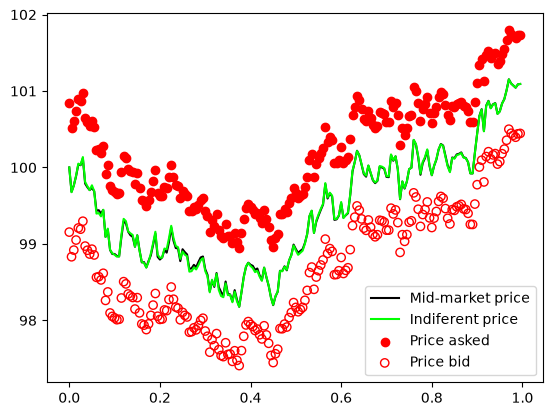

In [6]:
plt.plot(df["t"],df["s"], label="Mid-market price",color="black")
plt.plot(df["t"],df["r"], label="Indiferent price",color="lime")
plt.scatter(df["t"],df["pa"], label="Price asked",color="red")
plt.scatter(df["t"],df["pb"], label="Price bid",color="red",facecolors="none")

plt.legend()
plt.show()

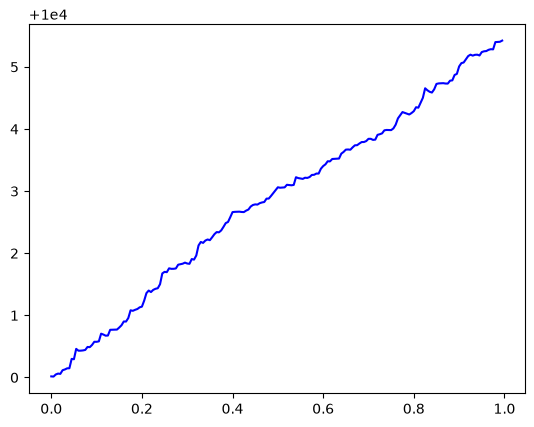

In [7]:
plt.plot(df["t"],df["wealth"], label="Wealth",color="blue")
plt.show()

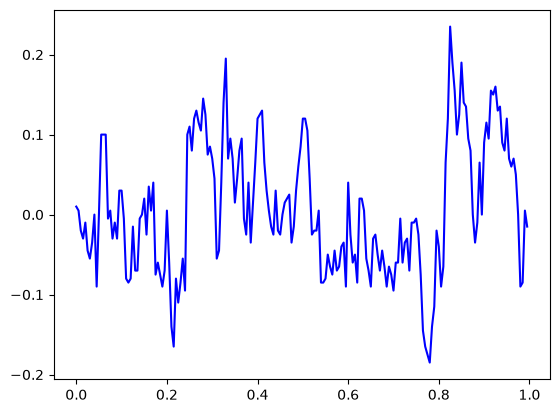

In [9]:
plt.plot(df["t"],df["q"], label="inventory",color="blue")
plt.show()